In [2]:
%pip install matplotlib

  Using cached matplotlib-3.10.8-cp311-cp311-macosx_11_0_arm64.whl.metadata (52 kB)
  Using cached contourpy-1.3.3-cp311-cp311-macosx_11_0_arm64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.61.1-cp311-cp311-macosx_10_9_universal2.whl.metadata (114 kB)
  Using cached kiwisolver-1.4.9-cp311-cp311-macosx_11_0_arm64.whl.metadata (6.3 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
Using cached matplotlib-3.10.8-cp311-cp311-macosx_11_0_arm64.whl (8.1 MB)
Using cached contourpy-1.3.3-cp311-cp311-macosx_11_0_arm64.whl (270 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.61.1-cp311-cp311-macosx_10_9_universal2.whl (2.9 MB)
Using cached kiwisolver-1.4.9-cp311-cp311-macosx_11_0_arm64.whl (65 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 18.6 MB/s  0:00:00 eta 0:00:01
Using cached pyparsing-3.3.2-py3-none-any.whl (122 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

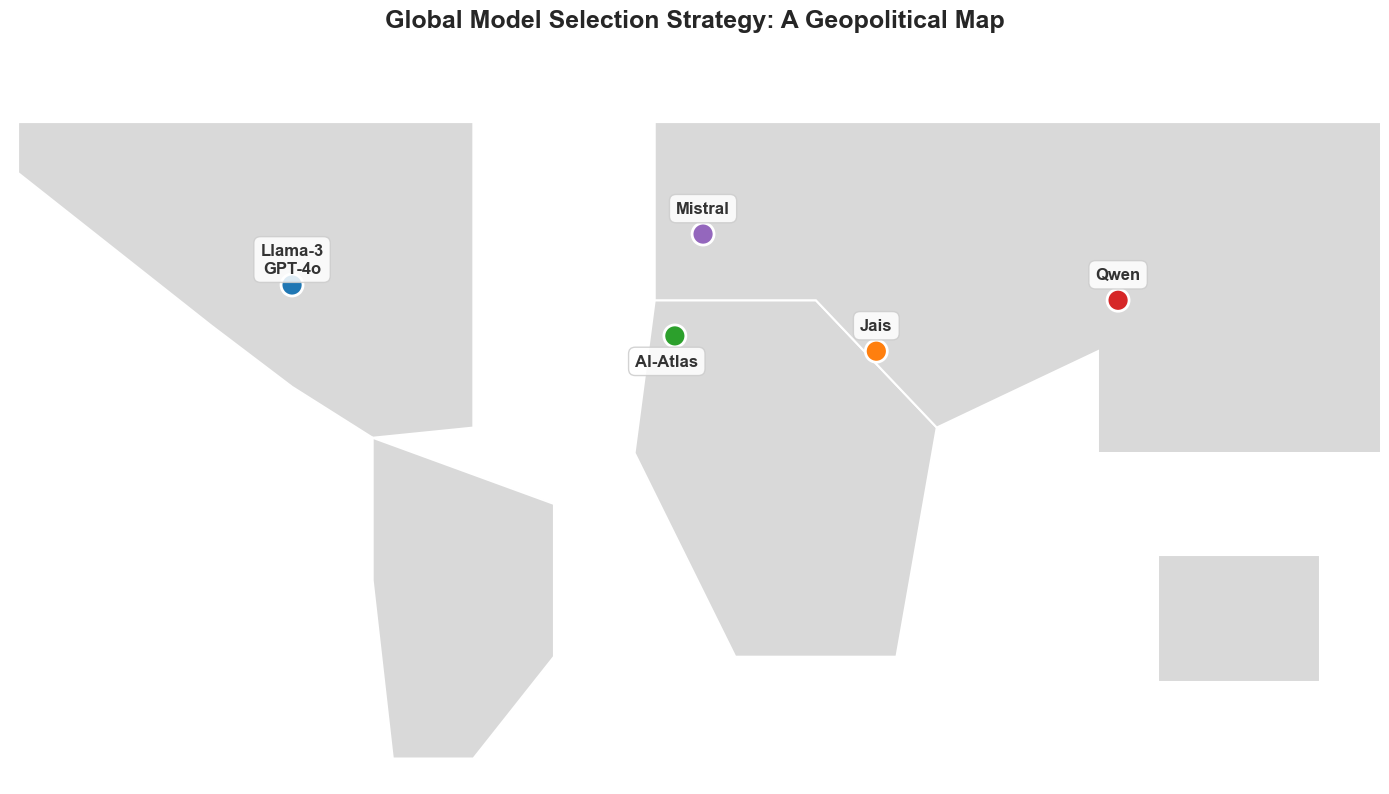

In [3]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd
import numpy as np

# 设置风格
plt.style.use('seaborn-v0_8-white')

# ==========================================
# 1. 准备数据：模型名称和大致经纬度
# ==========================================
data = [
    # North America (Combined label to avoid clutter)
    {"Label": "Llama-3\nGPT-4o", "Lon": -100, "Lat": 38, "Color": "#1f77b4"}, # Blue
    # Europe
    {"Label": "Mistral", "Lon": 2, "Lat": 48, "Color": "#9467bd"}, # Purple
    # Middle East
    {"Label": "Jais", "Lon": 45, "Lat": 25, "Color": "#ff7f0e"}, # Orange
    # North Africa
    {"Label": "Al-Atlas", "Lon": -5, "Lat": 28, "Color": "#2ca02c"}, # Green
    # Asia
    {"Label": "Qwen", "Lon": 105, "Lat": 35, "Color": "#d62728"}, # Red
]
df = pd.DataFrame(data)

# ==========================================
# 2. 简化的世界地图轮廓数据 (内嵌数据，无需外部库)
# ==========================================
# 这些是大陆的大致多边形轮廓
WORLD_MAP_POLYGONS = [
    # North America
    [(-168, 70), (-55, 70), (-55, 10), (-80, 8), (-100, 18), (-120, 30), (-168, 60)],
    # South America
    [(-80, 8), (-35, -5), (-35, -35), (-55, -55), (-75, -55), (-80, -20), (-80, 8)],
    # Eurasia + Africa (Simplified unified landmass for visual context)
    [(-10, 35), (30, 35), (60, 10), (50, -35), (10, -35), (-15, 5), (-10, 35)], # Africa part
    [(-10, 35), (-10, 70), (180, 70), (180, 5), (100, 5), (100, 25), (60, 10), (30, 35), (-10, 35)], # Eurasia part
    # Australia
    [(115, -15), (155, -15), (155, -40), (115, -40)]
]

# ==========================================
# 3. 绘图
# ==========================================
fig, ax = plt.subplots(figsize=(14, 8))

# --- 绘制地图背景 ---
ax.set_facecolor('#e6f2ff') # 海洋颜色 (浅蓝)
for polygon_coords in WORLD_MAP_POLYGONS:
    poly = patches.Polygon(polygon_coords, closed=True, 
                           facecolor='#d9d9d9', edgecolor='white', linewidth=1.5, zorder=1)
    ax.add_patch(poly)

# 设置显示范围
ax.set_xlim(-170, 170)
ax.set_ylim(-60, 80)
ax.axis('off') # 隐藏坐标轴

# --- 绘制模型点和标签 ---
# 画点
ax.scatter(df['Lon'], df['Lat'], color=df['Color'], s=250, 
           edgecolors='white', linewidth=2, zorder=10)

# 画标签
for i, row in df.iterrows():
    # 微调标签位置，避免挡住点
    offset_x = 0
    offset_y = 5
    if "Al-Atlas" in row['Label']:
         offset_y = -5 # Al-Atlas 放在点下方，避免和 Mistral 重叠
         offset_x = -2

    ax.text(row['Lon'] + offset_x, row['Lat'] + offset_y, row['Label'], 
            fontsize=12, fontweight='bold', color='#333333',
            ha='center', va='center', zorder=11,
            bbox=dict(facecolor='white', alpha=0.85, edgecolor='#cccccc', boxstyle='round,pad=0.4'))

# --- 添加标题 ---
plt.title("Global Model Selection Strategy: A Geopolitical Map", fontsize=18, fontweight='bold', y=1.05)

plt.tight_layout()
# 保存图片
plt.savefig('global_model_map_final.png', dpi=150, bbox_inches='tight')
plt.show()